In [15]:
import pandas as pd
import numpy as np
from collections import Counter
import ast
import matplotlib.pyplot as plt
import torch
import math
import seaborn as sns
import os
import sys
from pathlib import Path

# Go one directory up from analysis/
project_root = Path.cwd().parent

sys.path.insert(0, str(project_root))

from explainer import get_explain_parser
from exp.exp_main import Exp_Main
from main import make_setting, set_seed
from vis.utils_explainer import evaluate_edge_faithfulness, predict_with_edges

In [16]:
args = get_explain_parser().parse_args([
    "--model", "GCN",
    "--model_id", "oct24",
    "--data_path", "../data/train_50w.csv",
    "--function_words", "../data/function_words.txt",
    "--graph_type", "wan",
    "--wan_source", "text",
    "--window", "5",
    "--node_features", "emb",
    "--embeddings", "glove-wiki-gigaword-100",
    "--edge_weight", "wan",
    "--learning_rate", "0.001",
    "--num_layers", "2",
    "--hidden_dim", "64",
    "--readout", "sum",
    "--seed", "2029",
    "--itr", "1",
    "--node_mask_type", "none",
    "--edge_mask_type", "object",
    "--explain_epochs", "200",
    "--checkpoints", "../checkpoints",
    "--results_dir", "../results"
])

set_seed(args.seed)

setting = make_setting(args, args.seed)

exp = Exp_Main(args)

ckpt = os.path.join(
    args.checkpoints,
    setting,
    "checkpoint.pth"
)

exp.model.load_state_dict(
    torch.load(ckpt, map_location=exp.device, weights_only=True)
)

model = exp.model.eval()
device = exp.device

folder = os.path.join(args.results_dir, setting)

results = torch.load(
    os.path.join(folder, "explanations_none_object.pth"),
    map_location="cpu",
    weights_only=False
)

Use CPU
train 1680
GCN: 25,794 trainable parameters, input dim 100


In [ ]:
def evaluate_faithfulness_thresholds(
    results,
    model,
    device,
    folder,
    path_base,
    fractions=None,
    seed=2029,
    random_repeats=100
):

    if fractions is None:
        fractions = [
            0.05, 0.10, 0.15, 0.20,
            0.25, 0.30, 0.40, 0.50,
            0.60, 0.70, 0.80, 0.90, 1.00
        ]

    all_results = []

    for fraction in fractions:

        print(f"Evaluating top {fraction * 100:.0f}% edges...")

        # Use your ORIGINAL evaluation function
        df = evaluate_edge_faithfulness(
            results=results,
            folder=folder,
            path_base=path_base,
            model=model,
            device=device,
            seed=seed,
            fraction=fraction,
            top_k=None,
            random_repeats=random_repeats
        )

        # Add threshold information
        df["fraction"] = fraction
        df["percentage"] = fraction * 100

        all_results.append(df)

    df_curve = pd.concat(
        all_results,
        ignore_index=True
    )

    return df_curve

def plot_faithfulness_thresholds(df, show_random=True):

    metrics = {
        "comprehensiveness": "Comprehensiveness (Higher is Better)",
        "sufficiency": "Sufficiency (Lower is Better)"
    }

    colors = {
        "Human": "tab:blue",
        "Machine": "tab:orange"
    }

    fig, axes = plt.subplots(
        1, 2,
        figsize=(16, 6)
    )

    for ax, (metric, title) in zip(axes, metrics.items()):

        for class_name in ["Human", "Machine"]:

            class_df = df[df["class"] == class_name]

            summary = (
                class_df.groupby("percentage")[metric]
                .median()
                .sort_index()
            )

            ax.plot(
                summary.index,
                summary.values,
                color=colors[class_name],
                linestyle="-",
                marker="o",
                linewidth=2,
                label=f"{class_name} - GNNExplainer"
            )

            if show_random:

                summary_random = (
                    class_df.groupby("percentage")[f"{metric}_random"]
                    .median()
                    .sort_index()
                )

                ax.plot(
                    summary_random.index,
                    summary_random.values,
                    color=colors[class_name],
                    linestyle="--",
                    marker="s",
                    linewidth=2,
                    label=f"{class_name} - Random"
                )

        ax.axhline(
            0,
            color="gray",
            linestyle=":",
            linewidth=1
        )

        ax.set_title(title)
        ax.set_xlabel("Percentage of Selected Edges (%)")
        ax.set_ylabel("Median Confidence Difference")

        ax.set_xticks(
            sorted(df["percentage"].unique())
        )

        ax.grid(alpha=0.3)
        ax.legend()

    plt.tight_layout()
    plt.show()

Evaluating top 5% edges...
Evaluating top 10% edges...
Evaluating top 15% edges...
Evaluating top 20% edges...
Evaluating top 25% edges...
Evaluating top 30% edges...
Evaluating top 40% edges...
Evaluating top 50% edges...
Evaluating top 60% edges...
Evaluating top 70% edges...
Evaluating top 80% edges...
Evaluating top 90% edges...
Evaluating top 100% edges...


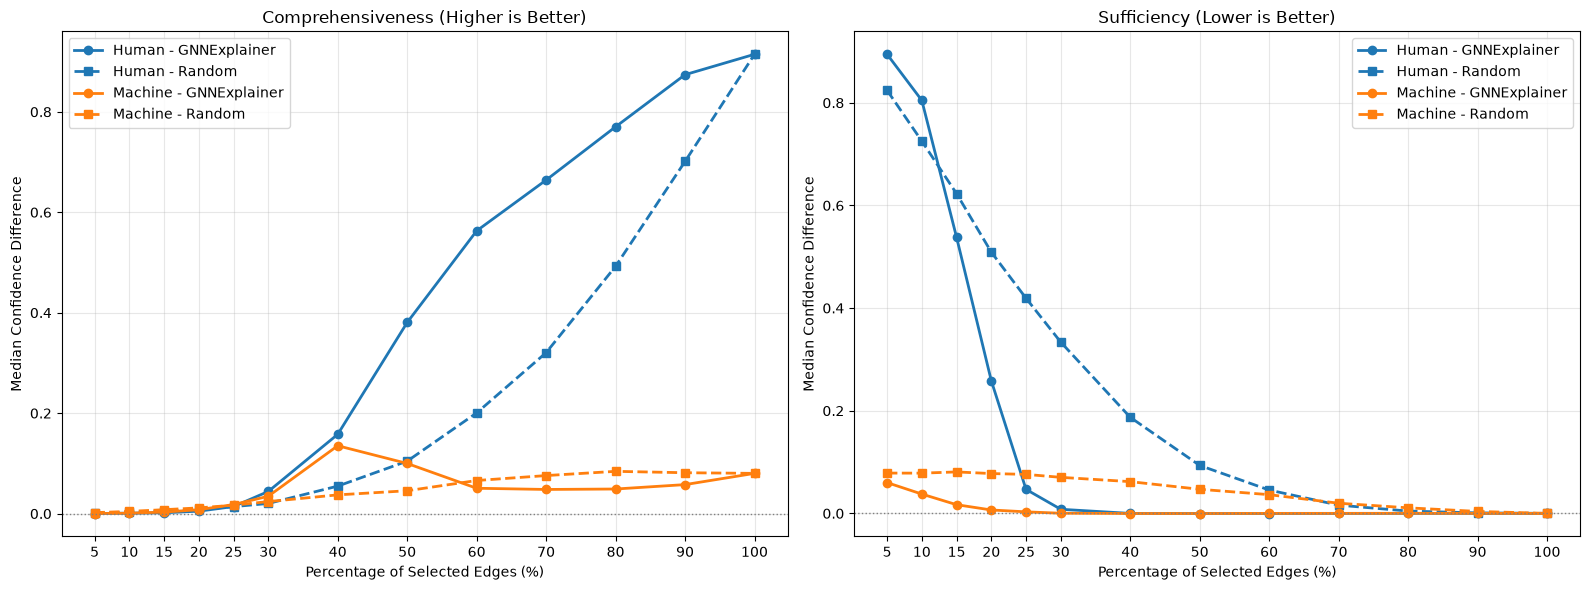

comprehensiveness  comprehensiveness_random  sufficiency  \
percentage class                                                               
5.0        Human               0.0002                    0.0010       0.8945   
           Machine             0.0002                    0.0020       0.0599   
10.0       Human               0.0009                    0.0025       0.8046   
           Machine             0.0008                    0.0044       0.0376   
15.0       Human               0.0017                    0.0047       0.5379   
           Machine             0.0030                    0.0078       0.0169   
20.0       Human               0.0049                    0.0083       0.2584   
           Machine             0.0078                    0.0114       0.0066   
25.0       Human               0.0141                    0.0139       0.0468   
           Machine             0.0180                    0.0168       0.0030   
30.0       Human               0.0441                    0.0202       0.0080   
           Machine             0.0346                    0.0240       0.0003   
40.0       Human               0.1579                    0.0548      -0.0000   
           Machine             0.1352                    0.0373      -0.0002   
50.0       Human               0.3806                    0.1045      -0.0003   
           Machine             0.0999                    0.0456      -0.0003   
60.0       Human               0.5630                    0.2005      -0.0003   
           Machine             0.0505                    0.0659      -0.0000   
70.0       Human               0.6642                    0.3205      -0.0001   
           Machine             0.0481                    0.0758       0.0000   
80.0       Human               0.7702                    0.4925      -0.0000   
           Machine             0.0490                    0.0842       0.0001   
90.0       Human               0.8740                    0.7012      -0.0000   
           Machine             0.0578                    0.0814       0.0001   
100.0      Human               0.9146                    0.9146       0.0000   
           Machine             0.0802                    0.0802       0.0000   

                    sufficiency_random  
percentage class                        
5.0        Human                0.8242  
           Machine              0.0785  
10.0       Human                0.7252  
           Machine              0.0784  
15.0       Human                0.6229  
           Machine              0.0808  
20.0       Human                0.5090  
           Machine              0.0776  
25.0       Human                0.4192  
           Machine              0.0760  
30.0       Human                0.3337  
           Machine              0.0702  
40.0       Human                0.1872  
           Machine              0.0618  
50.0       Human                0.0934  
           Machine              0.0470  
60.0       Human                0.0455  
           Machine              0.0365  
70.0       Human                0.0161  
           Machine              0.0198  
80.0       Human                0.0045  
           Machine              0.0108  
90.0       Human                0.0010  
           Machine              0.0038  
100.0      Human                0.0000  
           Machine              0.0000

In [ ]:
df_curve = evaluate_faithfulness_thresholds(
    results=results,
    model=model,
    device=device,
    folder=folder,
    path_base="noob",
    seed=2029,
    random_repeats=100
)

plot_faithfulness_thresholds(df_curve)